# Tesis: Optimización Operativa en ETAP

## 1. Objetivo y alcance
El objetivo de este proyecto es **pronosticar exclusivamente la cantidad mensual de viajes especiales** realizados por la empresa ETAP.

Cada registro en nuestra base de datos (`Historial Viajes Especiales.xlsx`) representa un viaje válido y confirmado. No se realizarán eliminaciones de registros por coincidencias de fechas o destinos, ya que el enfoque está puesto en el volumen total de servicios prestados mensualmente. Tampoco se abordará en esta instancia el dimensionamiento de la flota ni la asignación por tipo de unidad.


## 2. Configuración e importación de librerías
En esta sección importamos las librerías fundamentales para el manejo y visualización de los datos. Además, fijamos una semilla (seed) para garantizar que cualquier proceso aleatorio sea reproducible.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuración visual
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

# Fijar semilla para reproducibilidad
np.random.seed(42)

print("Librerías importadas y entorno configurado exitosamente.")

Librerías importadas y entorno configurado exitosamente.


## 3. Parámetros y rutas
Conectamos el entorno a Google Drive y definimos la ruta principal del proyecto y los nombres de los archivos. Esto centraliza la configuración y evita errores de tipeo en pasos posteriores.

In [ ]:
repo_url = "https://github.com/GustaCarhue/Seminario-de-Trabajo-Final"

url_etap = f"{repo_url}/Historial%20Viajes%20Especiales.xlsx"  # El espacio se reemplaza por %20
url_tc = f"{repo_url}/Tipo%20de%20cambio%20(BCRA).xls"
url_indec = f"{repo_url}/INDEC%20Historial.csv"
url_ipc = f"{repo_url}/IPC.csv"
url_hoteles = f"{repo_url}/Ocupacion%20Hotel.csv"

print("Rutas de archivos configuradas desde GitHub.")

Mounted at /content/gdrive

Directorio de trabajo configurado en: /content/gdrive/MyDrive/UGR/Seminario de Trabajo Final/Tesina Gonzalez Dupouy - Pretzsch


## 4. Carga de datos
Procedemos a cargar en memoria (DataFrames) tanto la base interna de ETAP como las fuentes de información exógenas. Verificamos las dimensiones de cada tabla para confirmar la carga inicial.

In [ ]:
import pandas as pd

print("🌐 Configurando enlaces directos desde GitHub...")

# Enlaces absolutos y directos en formato Raw
url_etap = "https://githubusercontent.com"
url_tc = "https://githubusercontent.com"
url_indec = "https://githubusercontent.com"
url_ipc = "https://githubusercontent.com"
url_hoteles = "https://githubusercontent.com"

print("Iniciando carga de datos...\n")

# 1. Carga de base principal (ETAP)
df_etap_raw = pd.read_excel(url_etap)
print(f"✅ ETAP (Historial): {df_etap_raw.shape[0]} filas, {df_etap_raw.shape[1]} columnas")

# 2. Carga de datos exógenos (BCRA)
# Nota: Si este archivo tira error, puede requerir !pip install xlrd en una celda previa
df_tc_raw = pd.read_excel(url_tc, header=None)
print(f"✅ Tipo de Cambio: {df_tc_raw.shape[0]} filas, {df_tc_raw.shape[1]} columnas")

# 3. Carga de INDEC
df_indec_raw = pd.read_csv(url_indec)
print(f"✅ INDEC (EMAE): {df_indec_raw.shape[0]} filas, {df_indec_raw.shape[1]} columnas")

# 4. Carga de IPC
df_ipc_raw = pd.read_csv(url_ipc)
print(f"✅ IPC: {df_ipc_raw.shape[0]} filas, {df_ipc_raw.shape[1]} columnas")

# 5. Carga de Ocupación Hotelera
df_hoteles_raw = pd.read_csv(url_hoteles)
print(f"✅ Ocupación Hotelera: {df_hoteles_raw.shape[0]} filas, {df_hoteles_raw.shape[1]} columnas")

print("\n🚀 Carga de datos completada con éxito desde GitHub.")


Iniciando carga de datos...

✅ ETAP (Historial): 1931 filas, 10 columnas
✅ Tipo de Cambio: 5906 filas, 6 columnas
✅ INDEC (EMAE): 265 filas, 7 columnas
✅ IPC: 111 filas, 22 columnas
✅ Ocupación Hotelera: 454 filas, 4 columnas

🚀 Carga de datos completada.


## 5. Validación inicial
Inspeccionamos la estructura de la base interna de ETAP para conocer sus variables, tipos de datos, cantidad de valores nulos y una vista previa de los registros.

In [ ]:
# Información general del DataFrame de ETAP
print("--- INFO DEL DATAFRAME ETAP ---")
df_etap_raw.info()

print("\n--- VALORES NULOS POR COLUMNA ---")
print(df_etap_raw.isna().sum())

print("\n--- MUESTRA DE 5 REGISTROS ---")
display(df_etap_raw.head())

--- INFO DEL DATAFRAME ETAP ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1931 entries, 0 to 1930
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Desde         1931 non-null   datetime64[ns]
 1   Hasta         1931 non-null   datetime64[ns]
 2   Contratante   1931 non-null   object        
 3   Origen        1931 non-null   object        
 4   Destino       1931 non-null   object        
 5   Habilitación  1931 non-null   object        
 6   Kilómetros    1931 non-null   int64         
 7   Capacidad     1931 non-null   int64         
 8   Tipo          1931 non-null   object        
 9   Interno       1931 non-null   object        
dtypes: datetime64[ns](2), int64(2), object(6)
memory usage: 151.0+ KB

--- VALORES NULOS POR COLUMNA ---
Desde           0
Hasta           0
Contratante     0
Origen          0
Destino         0
Habilitación    0
Kilómetros      0
Capacidad       0
Tipo       

,Desde,Hasta,Contratante,Origen,Destino,Habilitación,Kilómetros,Capacidad,Tipo,Interno
0,2021-01-04,2021-01-04,Aleisa,Comodoro Rivadavia,Caleta Olivia,Nacional,180,40,Piso Elevado,381
1,2021-01-07,2021-01-07,Comodoro Deportes,Comodoro Rivadavia,Rawson,Provincial,800,62,Doble Piso,212
2,2021-01-07,2021-01-07,Comodoro Deportes,Comodoro Rivadavia,Rawson,Provincial,800,60,Doble Piso,353
3,2021-01-09,2021-01-14,La Salada,Comodoro Rivadavia,Buenos Aires,Nacional,3600,34,Piso Elevado,230
4,2021-01-09,2021-01-14,La Salada,Comodoro Rivadavia,Buenos Aires,Nacional,3600,34,Piso Elevado,231


## 6. Limpieza de la base ETAP
Trabajamos sobre una copia de los datos originales. Normalizaremos los nombres de las columnas a minúsculas sin espacios para facilitar su manipulación. Aseguraremos que la columna principal de fecha (`desde`) tenga el formato de tiempo correcto.

*Requisito: Mantener estrictamente los 1.931 registros válidos.*

In [ ]:
# 1. Crear copia de trabajo
df_etap_clean = df_etap_raw.copy()

# 2. Normalizar nombres de columnas (minúsculas, guiones bajos)
df_etap_clean.columns = [col.strip().lower().replace(' ', '_') for col in df_etap_clean.columns]

# 3. Convertir columna de fecha 'desde' a datetime
# Asumimos que la columna se llama 'desde', forzamos coerción si hay errores
df_etap_clean['desde'] = pd.to_datetime(df_etap_clean['desde'], errors='coerce')

# Validar fechas nulas generadas por la conversión
fechas_nulas = df_etap_clean['desde'].isna().sum()
if fechas_nulas > 0:
    print(f"⚠️ Advertencia: Se encontraron {fechas_nulas} fechas inválidas.")

# 4. Validar el tamaño final
filas_finales = df_etap_clean.shape[0]
print(f"\nFilas en la base limpia: {filas_finales}")
assert filas_finales == 1931, f"Error: La base debía tener 1931 registros, pero tiene {filas_finales}"
print("✅ Se conservan los 1.931 registros correctamente.")


Filas en la base limpia: 1931
✅ Se conservan los 1.931 registros correctamente.


## 7. Construcción de la serie mensual
Agruparemos los viajes contabilizando un viaje por cada fila, asignándolos al mes indicado por la variable `desde`. Construiremos una serie temporal continua desde **Enero 2021** hasta **Diciembre 2025**, garantizando que no falte ningún mes (rellenando con ceros si fuese necesario).

Finalmente validaremos la suma y graficaremos la evolución.

Cantidad de meses en la serie: 60
Suma total de viajes: 1931
✅ Validaciones superadas con éxito.



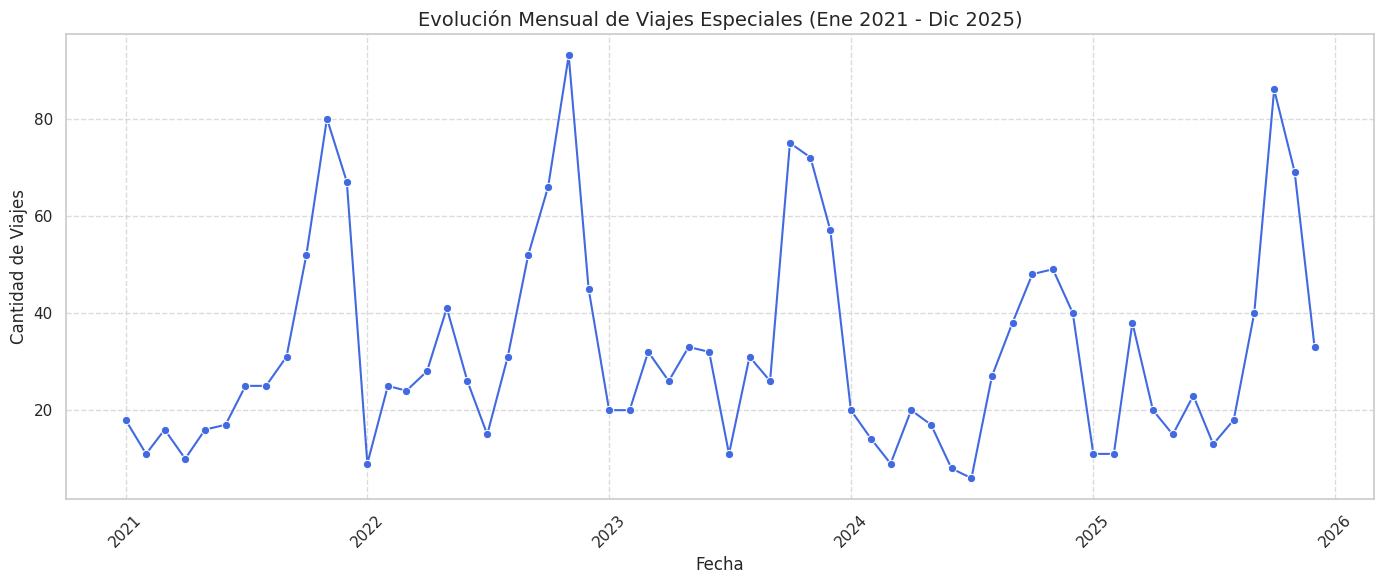

In [ ]:
# 1. Truncar la fecha al inicio del mes (YYYY-MM-01)
df_etap_clean['mes_anio'] = df_etap_clean['desde'].dt.to_period('M').dt.to_timestamp()

# 2. Agrupar y contar
df_mensual = df_etap_clean.groupby('mes_anio').size().reset_index(name='cantidad_viajes')

# 3. Crear un rango de fechas continuo (Ene 2021 a Dic 2025)
rango_fechas = pd.date_range(start='2021-01-01', end='2025-12-01', freq='MS')
df_mensual = df_mensual.set_index('mes_anio').reindex(rango_fechas, fill_value=0).reset_index()
df_mensual.rename(columns={'index': 'mes_anio'}, inplace=True)

# --- VALIDACIONES SOLICITADAS ---
meses_totales = len(df_mensual)
viajes_totales = df_mensual['cantidad_viajes'].sum()

print(f"Cantidad de meses en la serie: {meses_totales}")
print(f"Suma total de viajes: {viajes_totales}")

assert meses_totales == 60, "Error: La serie no tiene 60 meses."
assert df_mensual['mes_anio'].isna().sum() == 0, "Error: Hay meses faltantes/Nulos."
assert viajes_totales == 1931, f"Error: La suma de viajes es {viajes_totales}, debía ser 1931."
print("✅ Validaciones superadas con éxito.\n")

# --- GRÁFICO DE EVOLUCIÓN ---
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_mensual, x='mes_anio', y='cantidad_viajes', marker='o', color='royalblue')
plt.title('Evolución Mensual de Viajes Especiales (Ene 2021 - Dic 2025)', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Cantidad de Viajes', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 8. Preparación de variables exógenas
Limpiamos y llevamos a frecuencia mensual las distintas fuentes de datos externos.
Mantendremos exclusivamente el período de interés (2021-2025) y evitaremos cualquier tipo de imputación (no usaremos `bfill` ni inventaremos valores faltantes) o generación de rezagos temporales en esta instancia.

In [ ]:
print("Procesando variables exógenas...\n")

# Función auxiliar para filtrar rango de interés
mask_rango = lambda df: (df['mes_anio'] >= '2021-01-01') & (df['mes_anio'] <= '2025-12-01')

# 8.1 Tipo de Cambio (BCRA) - Promedio Mensual (Lógica Corregida)
col_fecha = None
for col in df_tc_raw.columns:
    if df_tc_raw[col].astype(str).str.contains('Fecha', case=False, na=False).any():
        col_fecha = col
        break

if col_fecha is not None:
    col_tc = col_fecha + 1
    df_tc = df_tc_raw[[col_fecha, col_tc]].copy()
    df_tc.columns = ['fecha', 'tc']
    df_tc['fecha'] = pd.to_datetime(df_tc['fecha'], errors='coerce')
    if df_tc['tc'].dtype == object:
        df_tc['tc'] = df_tc['tc'].astype(str).str.replace(',', '.')
    df_tc['tc'] = pd.to_numeric(df_tc['tc'], errors='coerce')
    df_tc = df_tc.dropna(subset=['fecha', 'tc'])
    df_tc['mes_anio'] = df_tc['fecha'].dt.to_period('M').dt.to_timestamp()
    df_tc_mensual = df_tc.groupby('mes_anio')['tc'].mean().reset_index()
    df_tc_mensual.rename(columns={'tc': 'tipo_cambio'}, inplace=True)
    df_tc_mensual = df_tc_mensual[mask_rango(df_tc_mensual)]
else:
    raise ValueError("Error: No se detectó la columna 'Fecha' en el archivo del BCRA.")

# 8.2 IPC Nacional
df_ipc = df_ipc_raw[['indice_tiempo', 'ipc_ng_nacional']].copy()
df_ipc['mes_anio'] = pd.to_datetime(df_ipc['indice_tiempo'], errors='coerce')
df_ipc_mensual = df_ipc[['mes_anio', 'ipc_ng_nacional']]
df_ipc_mensual = df_ipc_mensual[mask_rango(df_ipc_mensual)]

# 8.3 EMAE Original
df_emae = df_indec_raw[['indice_tiempo', 'emae_original']].copy()
df_emae['mes_anio'] = pd.to_datetime(df_emae['indice_tiempo'], errors='coerce')
df_emae_mensual = df_emae[['mes_anio', 'emae_original']]
df_emae_mensual = df_emae_mensual[mask_rango(df_emae_mensual)]

# 8.4 Pernoctes Hoteleros Totales
df_hoteles = df_hoteles_raw[['indice_tiempo', 'pernoctes']].copy()
df_hoteles['mes_anio'] = pd.to_datetime(df_hoteles['indice_tiempo'], errors='coerce')
df_hoteles_mensual = df_hoteles.groupby('mes_anio')['pernoctes'].sum().reset_index()
df_hoteles_mensual = df_hoteles_mensual[mask_rango(df_hoteles_mensual)]

print("✅ Tipo de cambio mensualizado y filtrado (Corregido).")
print("✅ IPC nacional mensualizado y filtrado.")
print("✅ EMAE original mensualizado y filtrado.")
print("✅ Pernoctes agregados por mes y filtrados.")

Procesando variables exógenas...

✅ Tipo de cambio mensualizado y filtrado (Corregido).
✅ IPC nacional mensualizado y filtrado.
✅ EMAE original mensualizado y filtrado.
✅ Pernoctes agregados por mes y filtrados.


## 9. Integración del dataset mensual
Unificamos las variables exógenas con nuestra serie objetivo de cantidad de viajes mediante la clave `mes_anio`. Conservamos todos los 60 meses de la serie base para nuestro período (2021-2025).

In [ ]:
# Merge (Left join sobre la serie base df_mensual)
df_master = df_mensual.copy()
df_master = df_master.merge(df_tc_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_ipc_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_emae_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_hoteles_mensual, on='mes_anio', how='left')

# Validaciones y reportes
print(f"Dimensiones del dataset integrado: {df_master.shape[0]} filas x {df_master.shape[1]} columnas")
print(f"Período: {df_master['mes_anio'].min().strftime('%Y-%m')} a {df_master['mes_anio'].max().strftime('%Y-%m')}")
print("\nColumnas disponibles:")
print(list(df_master.columns))

print("\nValores faltantes por variable:")
print(df_master.isna().sum())

total_viajes = df_master['cantidad_viajes'].sum()
print(f"\nSuma total de cantidad_viajes: {total_viajes}")
assert total_viajes == 1931, f"Error: La suma de viajes es {total_viajes}, debía ser 1931."
print("✅ Confirmación superada: La variable objetivo sigue sumando exactamente 1.931 viajes.")

print("\n--- Tabla completa de 60 meses ---")
display(df_master)

Dimensiones del dataset integrado: 60 filas x 6 columnas
Período: 2021-01 a 2025-12

Columnas disponibles:
['mes_anio', 'cantidad_viajes', 'tipo_cambio', 'ipc_ng_nacional', 'emae_original', 'pernoctes']

Valores faltantes por variable:
mes_anio           0
cantidad_viajes    0
tipo_cambio        0
ipc_ng_nacional    0
emae_original      0
pernoctes          1
dtype: int64

Suma total de cantidad_viajes: 1931
✅ Confirmación superada: La variable objetivo sigue sumando exactamente 1.931 viajes.

--- Tabla completa de 60 meses ---


,mes_anio,cantidad_viajes,tipo_cambio,ipc_ng_nacional,emae_original,pernoctes
0,2021-01-01,18,85.970835,401.5071,131.521537,2809158.0
1,2021-02-01,11,88.674622,415.8595,126.239267,2839416.0
2,2021-03-01,16,91.066368,435.8657,145.956900,2072968.0
3,2021-04-01,10,92.863845,453.6503,147.280844,1389555.0
4,2021-05-01,16,94.104826,468.7250,151.169322,666592.0
5,2021-06-01,17,95.254290,483.6049,148.979617,629734.0
6,2021-07-01,25,96.237781,498.0987,142.425913,2251331.0
7,2021-08-01,25,97.213814,510.3942,140.974941,2201014.0
8,2021-09-01,31,98.284995,528.4968,141.296089,2384792.0
9,2021-10-01,52,99.249126,547.0802,139.514759,2841649.0


## 10. Análisis exploratorio
En esta sección realizamos el análisis descriptivo y visual de las variables que componen el dataset integrado. Analizamos el comportamiento temporal, la estacionalidad (mes a mes) y la autocorrelación de la variable objetivo.

**Nota Importante:** La correlación observada entre variables de forma contemporánea en este análisis exploratorio no implica causalidad. La utilidad predictiva real de las variables exógenas se evaluará más adelante mediante esquemas estrictos de validación fuera de muestra.

--- Estadísticos Descriptivos ---


,mes_anio,cantidad_viajes,tipo_cambio,ipc_ng_nacional,emae_original,pernoctes
count,60,60.00,60.00,60.00,60.00,59.00
mean,2023-06-16 20:48:00,32.18,536.49,3719.07,147.85,3573359.27
min,2021-01-01 00:00:00,6.00,85.97,401.51,126.24,629734.00
25%,2022-03-24 06:00:00,16.75,112.37,706.72,143.57,2840532.50
50%,2023-06-16 00:00:00,26.00,257.61,1763.85,148.01,3647293.00
75%,2024-09-08 12:00:00,40.25,966.76,7170.17,152.07,4103458.00
max,2025-12-01 00:00:00,93.00,1447.84,10121.37,164.88,6224087.00
std,NaN,21.35,473.83,3435.18,7.36,1127357.64


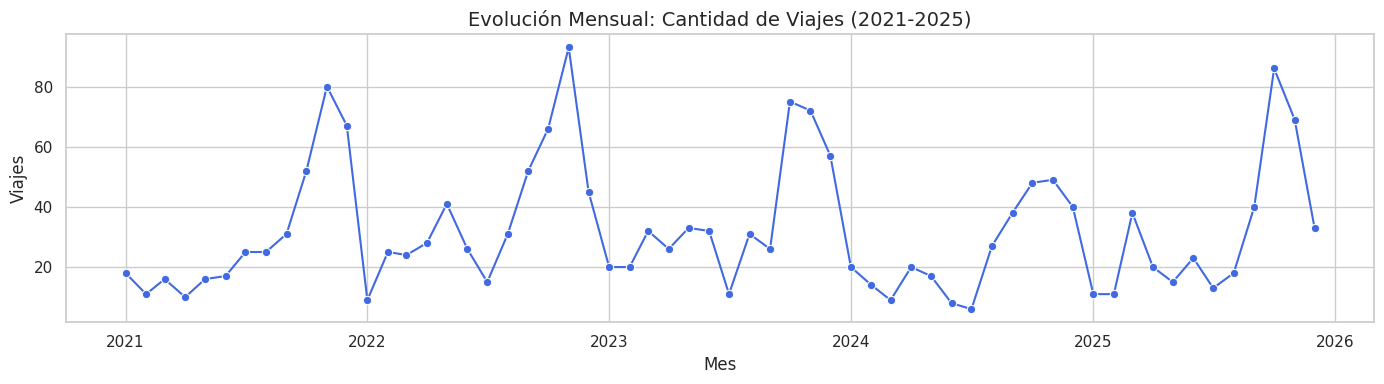

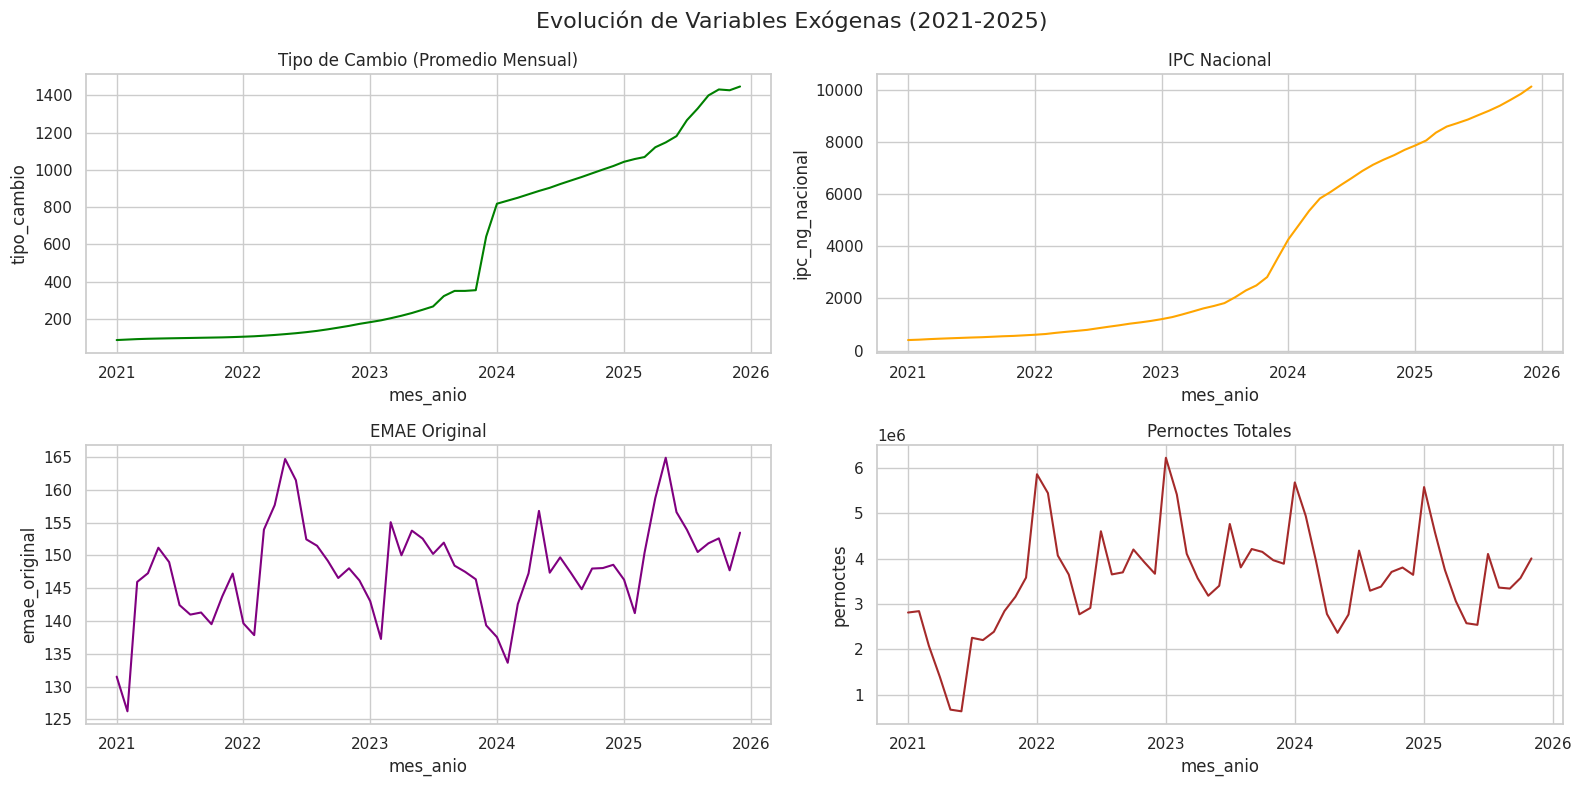

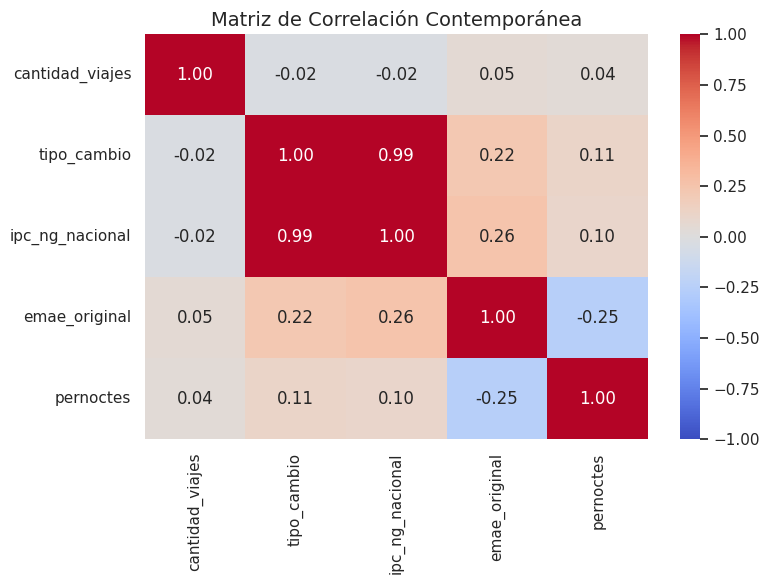

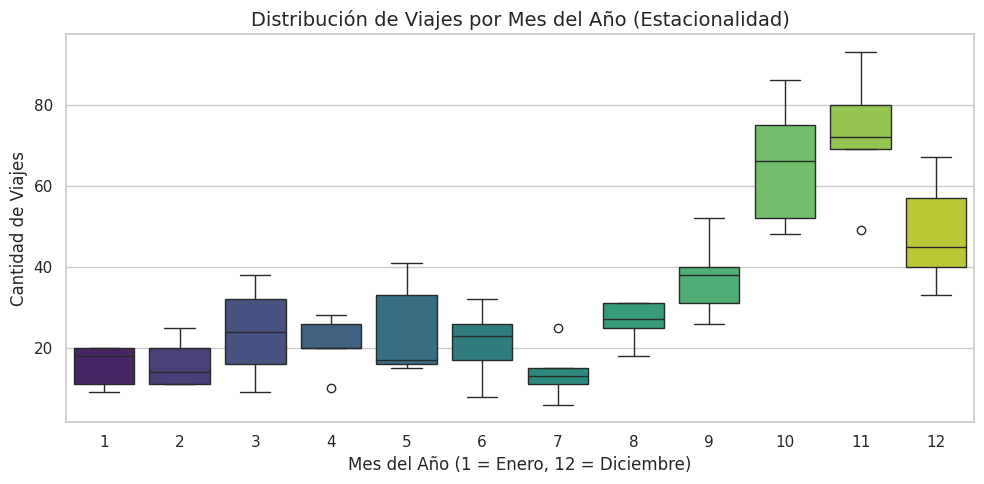

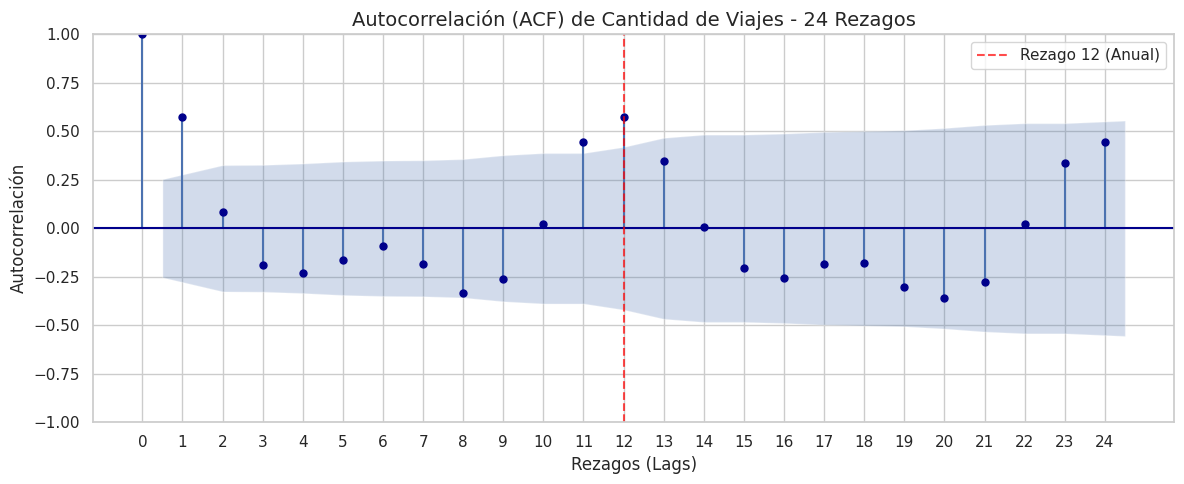

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# Estadísticos descriptivos
print("--- Estadísticos Descriptivos ---")
display(df_master.describe().round(2))

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. Gráfico de evolución de cantidad_viajes
plt.figure(figsize=(14, 4))
sns.lineplot(data=df_master, x='mes_anio', y='cantidad_viajes', marker='o', color='royalblue')
plt.title('Evolución Mensual: Cantidad de Viajes (2021-2025)', fontsize=14)
plt.xlabel('Mes')
plt.ylabel('Viajes')
plt.tight_layout()
plt.show()

# 2. Gráficos temporales de las variables exógenas
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('Evolución de Variables Exógenas (2021-2025)', fontsize=16)

sns.lineplot(ax=axes[0, 0], data=df_master, x='mes_anio', y='tipo_cambio', color='green')
axes[0, 0].set_title('Tipo de Cambio (Promedio Mensual)')

sns.lineplot(ax=axes[0, 1], data=df_master, x='mes_anio', y='ipc_ng_nacional', color='orange')
axes[0, 1].set_title('IPC Nacional')

sns.lineplot(ax=axes[1, 0], data=df_master, x='mes_anio', y='emae_original', color='purple')
axes[1, 0].set_title('EMAE Original')

sns.lineplot(ax=axes[1, 1], data=df_master, x='mes_anio', y='pernoctes', color='brown')
axes[1, 1].set_title('Pernoctes Totales')

plt.tight_layout()
plt.show()

# 3. Matriz de correlación contemporánea
plt.figure(figsize=(8, 6))
corr_matrix = df_master.drop(columns=['mes_anio']).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Matriz de Correlación Contemporánea', fontsize=14)
plt.tight_layout()
plt.show()

# 4. Comparación visual de viajes por mes del año (Estacionalidad)
df_master['mes_del_anio'] = df_master['mes_anio'].dt.month
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_master, x='mes_del_anio', y='cantidad_viajes', palette='viridis')
plt.title('Distribución de Viajes por Mes del Año (Estacionalidad)', fontsize=14)
plt.xlabel('Mes del Año (1 = Enero, 12 = Diciembre)')
plt.ylabel('Cantidad de Viajes')
plt.tight_layout()
plt.show()
df_master.drop(columns=['mes_del_anio'], inplace=True)

# 5. Autocorrelación de cantidad_viajes hasta 24 rezagos
plt.figure(figsize=(12, 5))
plot_acf(df_master['cantidad_viajes'], lags=24, ax=plt.gca(), alpha=0.05, color='darkblue')
plt.title('Autocorrelación (ACF) de Cantidad de Viajes - 24 Rezagos', fontsize=14)
plt.xlabel('Rezagos (Lags)')
plt.ylabel('Autocorrelación')
plt.xticks(range(0, 25))
plt.axvline(x=12, color='red', linestyle='--', alpha=0.7, label='Rezago 12 (Anual)')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Ingeniería de variables temporales
En esta sección construimos nuevas variables (features) a partir de la historia de los datos para capturar relaciones temporales. Nos aseguramos de aplicar los rezagos correctos, desplazando las medias móviles un mes hacia atrás (`shift(1)`) para evitar fugas de información (*data leakage*), y respetando la disponibilidad de las variables exógenas (sin interpolar valores hacia atrás).

In [ ]:
# Trabajar sobre una copia del dataset principal
df_features = df_master.copy()

# --- Variables Temporales Internas ---
# 1. Tendencia y componente mensual
df_features['tendencia'] = np.arange(1, len(df_features) + 1)
df_features['mes'] = df_features['mes_anio'].dt.month

# 2. Seno y Coseno del mes (Estacionalidad cíclica)
df_features['mes_sin'] = np.sin(2 * np.pi * df_features['mes'] / 12)
df_features['mes_cos'] = np.cos(2 * np.pi * df_features['mes'] / 12)

# 3. Rezagos (lags) de cantidad de viajes (1, 2, 3, 6, 12)
lags_objetivo = [1, 2, 3, 6, 12]
for lag in lags_objetivo:
    df_features[f'viajes_lag_{lag}'] = df_features['cantidad_viajes'].shift(lag)

# 4. Medias móviles de la variable objetivo (excluyendo el mes a predecir con shift(1))
df_features['viajes_ma_3'] = df_features['cantidad_viajes'].shift(1).rolling(window=3).mean()
df_features['viajes_ma_6'] = df_features['cantidad_viajes'].shift(1).rolling(window=6).mean()

# --- Variables Exógenas ---
# Respetamos el retraso de publicación oficial para simular escenarios reales.
df_features['tipo_cambio_lag_1'] = df_features['tipo_cambio'].shift(1)
df_features['ipc_ng_nacional_lag_1'] = df_features['ipc_ng_nacional'].shift(1)
df_features['emae_original_lag_2'] = df_features['emae_original'].shift(2)
df_features['pernoctes_lag_2'] = df_features['pernoctes'].shift(2)

# Mostrar las primeras 15 filas para comprobar los rezagos (se esperan valores NaN en las primeras filas)
print("--- Dataset con Ingeniería de Variables (Primeras 15 filas) ---")
display(df_features.head(15))

--- Dataset con Ingeniería de Variables (Primeras 15 filas) ---


,mes_anio,cantidad_viajes,tipo_cambio,ipc_ng_nacional,emae_original,pernoctes,tendencia,mes,mes_sin,mes_cos,...,viajes_lag_2,viajes_lag_3,viajes_lag_6,viajes_lag_12,viajes_ma_3,viajes_ma_6,tipo_cambio_lag_1,ipc_ng_nacional_lag_1,emae_original_lag_2,pernoctes_lag_2
0,2021-01-01,18,85.970835,401.5071,131.521537,2809158.0,1,1,5.000000e-01,8.660254e-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-02-01,11,88.674622,415.8595,126.239267,2839416.0,2,2,8.660254e-01,5.000000e-01,...,NaN,NaN,NaN,NaN,NaN,NaN,85.970835,401.5071,NaN,NaN
2,2021-03-01,16,91.066368,435.8657,145.956900,2072968.0,3,3,1.000000e+00,6.123234e-17,...,18.0,NaN,NaN,NaN,NaN,NaN,88.674622,415.8595,131.521537,2809158.0
3,2021-04-01,10,92.863845,453.6503,147.280844,1389555.0,4,4,8.660254e-01,-5.000000e-01,...,11.0,18.0,NaN,NaN,15.000000,NaN,91.066368,435.8657,126.239267,2839416.0
4,2021-05-01,16,94.104826,468.7250,151.169322,666592.0,5,5,5.000000e-01,-8.660254e-01,...,16.0,11.0,NaN,NaN,12.333333,NaN,92.863845,453.6503,145.956900,2072968.0
5,2021-06-01,17,95.254290,483.6049,148.979617,629734.0,6,6,1.224647e-16,-1.000000e+00,...,10.0,16.0,NaN,NaN,14.000000,NaN,94.104826,468.7250,147.280844,1389555.0
6,2021-07-01,25,96.237781,498.0987,142.425913,2251331.0,7,7,-5.000000e-01,-8.660254e-01,...,16.0,10.0,18.0,NaN,14.333333,14.666667,95.254290,483.6049,151.169322,666592.0
7,2021-08-01,25,97.213814,510.3942,140.974941,2201014.0,8,8,-8.660254e-01,-5.000000e-01,...,17.0,16.0,11.0,NaN,19.333333,15.833333,96.237781,498.0987,148.979617,629734.0
8,2021-09-01,31,98.284995,528.4968,141.296089,2384792.0,9,9,-1.000000e+00,-1.836970e-16,...,25.0,17.0,16.0,NaN,22.333333,18.166667,97.213814,510.3942,142.425913,2251331.0
9,2021-10-01,52,99.249126,547.0802,139.514759,2841649.0,10,10,-8.660254e-01,5.000000e-01,...,25.0,25.0,10.0,NaN,27.000000,20.666667,98.284995,528.4968,140.974941,2201014.0


## 12. Métricas de evaluación
Para medir el rendimiento de los modelos definimos las siguientes funciones:

* **MAE (Mean Absolute Error):** Mide el promedio de los errores en magnitud absoluta.
* **RMSE (Root Mean Squared Error):** Es la raíz del error cuadrático medio; penaliza con mayor dureza a los errores grandes.
* **MAPE (Mean Absolute Percentage Error):** Refleja el error como porcentaje del valor real (no útil si la serie tiene ceros reales).
* **sMAPE (Symmetric MAPE):** Aborda la asimetría del MAPE estabilizando el denominador.
* **MASE (Mean Absolute Scaled Error):** Compara el MAE de las predicciones contra el error medio de aplicar un modelo Naïve de rezago 1 **sólo** sobre los datos de entrenamiento. Un valor < 1 indica que el modelo propuesto superó a ese escenario base.

In [ ]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def mape(y_true, y_pred):
    # Máscara para evitar división por cero si hubiera viajes = 0
    mask = y_true != 0
    if not np.any(mask): return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def smape(y_true, y_pred):
    denominador = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    mask = denominador != 0
    if not np.any(mask): return np.nan
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denominador[mask]) * 100

def mase(y_true, y_pred, y_train):
    # y_train contiene los valores reales de entrenamiento.
    # El error Naïve in-sample se evalúa desplazando 1 paso (t vs t-1)
    if len(y_train) <= 1:
        return np.nan # Muy pocos datos para calcular el baseline

    mae_naive_train = np.mean(np.abs(y_train[1:] - y_train[:-1]))

    if mae_naive_train == 0:
        return np.nan
    return mae(y_true, y_pred) / mae_naive_train

print("✅ Funciones de métricas de validación definidas.")

✅ Funciones de métricas de validación definidas.


## 13. Protocolo de validación temporal
Para garantizar una evaluación rigurosa (out-of-sample) crearemos ventanas expansivas (*Expanding Windows*).

* **Entrenamiento y Validación:** Del año 2021 al 2024.
* **Prueba final (Holdout):** Todo el año 2025 queda completamente aislado e intocable.
* **Orígenes:** Evaluaremos orígenes de pronóstico dentro de los años 2023 y 2024.
* **Horizontes:** 1, 3 y 6 meses.

In [ ]:
# Excluimos 2025 por completo para la validación cruzada temporal
df_cv_base = df_features[df_features['mes_anio'] < '2025-01-01'].copy()

horizontes = [1, 3, 6]
cv_splits = []

# El primer mes posible a predecir (val_start) será enero de 2023.
# Generamos orígenes desde 2023-01-01 hasta 2024-12-01
fecha_origenes = pd.date_range(start='2023-01-01', end='2024-12-01', freq='MS')

for h in horizontes:
    for origen in fecha_origenes:
        val_start = origen
        val_end = origen + pd.DateOffset(months=h - 1)

        train_start = df_cv_base['mes_anio'].min()
        train_end = origen - pd.DateOffset(months=1)

        # Excluir cualquier ventana cuya validación caiga en 2025 o más allá
        if val_end >= pd.to_datetime('2025-01-01'):
            continue

        meses_train = len(pd.date_range(train_start, train_end, freq='MS'))
        meses_val = len(pd.date_range(val_start, val_end, freq='MS'))

        cv_splits.append({
            'horizonte': h,
            'origen': origen.strftime('%Y-%m'),
            'inicio_train': train_start.strftime('%Y-%m'),
            'fin_train': train_end.strftime('%Y-%m'),
            'inicio_val': val_start.strftime('%Y-%m'),
            'fin_val': val_end.strftime('%Y-%m'),
            'meses_train': meses_train,
            'meses_val': meses_val
        })

df_splits = pd.DataFrame(cv_splits)

# Confirmaciones y reportes
print(f"Total de ventanas generadas: {len(df_splits)}")
for h in horizontes:
    conteo = len(df_splits[df_splits['horizonte'] == h])
    print(f" - Horizonte {h} mes(es): {conteo} ventanas")

max_val_date = pd.to_datetime(df_splits['fin_val']).max()
print(f"\nFecha máxima alcanzada por validación: {max_val_date.strftime('%Y-%m')}")
assert max_val_date < pd.to_datetime('2025-01-01'), "ALERTA: Se han filtrado datos del año 2025."
print("✅ Confirmado: El año 2025 (Holdout) está completamente intacto y excluido de las ventanas.")

print("\n--- Muestra del Protocolo de Ventanas (Primeras 5 y Últimas 5) ---")
display(pd.concat([df_splits.head(5), df_splits.tail(5)]))

Total de ventanas generadas: 65
 - Horizonte 1 mes(es): 24 ventanas
 - Horizonte 3 mes(es): 22 ventanas
 - Horizonte 6 mes(es): 19 ventanas

Fecha máxima alcanzada por validación: 2024-12
✅ Confirmado: El año 2025 (Holdout) está completamente intacto y excluido de las ventanas.

--- Muestra del Protocolo de Ventanas (Primeras 5 y Últimas 5) ---


,horizonte,origen,inicio_train,fin_train,inicio_val,fin_val,meses_train,meses_val
0,1,2023-01,2021-01,2022-12,2023-01,2023-01,24,1
1,1,2023-02,2021-01,2023-01,2023-02,2023-02,25,1
2,1,2023-03,2021-01,2023-02,2023-03,2023-03,26,1
3,1,2023-04,2021-01,2023-03,2023-04,2023-04,27,1
4,1,2023-05,2021-01,2023-04,2023-05,2023-05,28,1
60,6,2024-03,2021-01,2024-02,2024-03,2024-08,38,6
61,6,2024-04,2021-01,2024-03,2024-04,2024-09,39,6
62,6,2024-05,2021-01,2024-04,2024-05,2024-10,40,6
63,6,2024-06,2021-01,2024-05,2024-06,2024-11,41,6
64,6,2024-07,2021-01,2024-06,2024-07,2024-12,42,6


## 14. Modelos de Línea Base (Baselines)

Antes de aplicar modelos de Machine Learning o estadísticos avanzados, establecemos puntos de referencia muy simples para comparar el rendimiento. Si un modelo avanzado no puede superar estas métricas, su complejidad no estará justificada.

Evaluaremos dos enfoques simples:
1. **Naïve Simple (Lag 1):** Asume que los próximos meses tendrán la misma cantidad de viajes que el *último mes* observado en el conjunto de entrenamiento.
2. **Naïve Estacional (Rezago 12):** Asume que el mes a predecir tendrá la misma cantidad de viajes que el *mismo mes del año anterior* (es decir, repite lo ocurrido hace 12 meses).

In [ ]:
import numpy as np
import pandas as pd

print("--- 14. Evaluación de Modelos Base (Baselines) ---")
print(f"Total de ventanas evaluadas: {len(df_splits)}")
print(f"Total de meses pronosticados: {df_splits['meses_val'].sum()}\n")

resultados_baselines = []

# Iterar por cada horizonte configurado (1, 3 y 6 meses)
for h in horizontes:
    y_true_all, y_pred_simple_all, y_pred_lag12_all = [], [], []
    mase_simple_windows, mase_lag12_windows = [], []

    # Filtrar las ventanas que corresponden a este horizonte
    splits_h = df_splits[df_splits['horizonte'] == h]

    for _, row in splits_h.iterrows():
        # Aislar los datos de entrenamiento y validación para esta ventana
        train_mask = (df_cv_base['mes_anio'] >= row['inicio_train']) & (df_cv_base['mes_anio'] <= row['fin_train'])
        val_mask = (df_cv_base['mes_anio'] >= row['inicio_val']) & (df_cv_base['mes_anio'] <= row['fin_val'])

        train_data = df_cv_base[train_mask]['cantidad_viajes'].values
        val_data = df_cv_base[val_mask]['cantidad_viajes'].values

        if len(val_data) == 0:
            continue

        # --- 1. Predicción Naïve Simple ---
        pred_simple = np.repeat(train_data[-1], len(val_data))

        # --- 2. Predicción Naïve Rezago 12 ---
        pred_lag12 = train_data[-12 : -12 + len(val_data)]

        y_true_all.extend(val_data)
        y_pred_simple_all.extend(pred_simple)
        y_pred_lag12_all.extend(pred_lag12)

        # Cálculo del MASE por ventana
        if len(train_data) > 1:
            mae_in_sample = np.mean(np.abs(train_data[1:] - train_data[:-1]))
            if mae_in_sample > 0:
                mase_simple_windows.append(mae(val_data, pred_simple) / mae_in_sample)
                mase_lag12_windows.append(mae(val_data, pred_lag12) / mae_in_sample)

    y_true_all = np.array(y_true_all)
    y_pred_simple_all = np.array(y_pred_simple_all)
    y_pred_lag12_all = np.array(y_pred_lag12_all)

    resultados_baselines.append({
        'Horizonte': h, 'Modelo': 'Naïve Simple',
        'MAE': mae(y_true_all, y_pred_simple_all),
        'RMSE': rmse(y_true_all, y_pred_simple_all),
        'MAPE': mape(y_true_all, y_pred_simple_all),
        'sMAPE': smape(y_true_all, y_pred_simple_all),
        'MASE': np.mean(mase_simple_windows) if mase_simple_windows else np.nan,
        'Fallos': 0, 'Ventanas': len(splits_h), 'Meses_Pred': len(y_true_all)
    })

    resultados_baselines.append({
        'Horizonte': h, 'Modelo': 'Naïve Rezago 12',
        'MAE': mae(y_true_all, y_pred_lag12_all),
        'RMSE': rmse(y_true_all, y_pred_lag12_all),
        'MAPE': mape(y_true_all, y_pred_lag12_all),
        'sMAPE': smape(y_true_all, y_pred_lag12_all),
        'MASE': np.mean(mase_lag12_windows) if mase_lag12_windows else np.nan,
        'Fallos': 0, 'Ventanas': len(splits_h), 'Meses_Pred': len(y_true_all)
    })

df_resultados_baselines = pd.DataFrame(resultados_baselines)
print("Resultados consolidados de Modelos Base (Validación Cruzada 2021-2024):")
display(df_resultados_baselines.round(2))


--- 14. Evaluación de Modelos Base (Baselines) ---
Total de ventanas evaluadas: 65
Total de meses pronosticados: 204

Resultados consolidados de Modelos Base (Validación Cruzada 2021-2024):


,Horizonte,Modelo,MAE,RMSE,MAPE,sMAPE,MASE,Fallos,Ventanas,Meses_Pred
0,1,Naïve Simple,12.04,16.76,51.43,44.98,0.85,0,24,24
1,1,Naïve Rezago 12,11.46,14.20,56.34,38.34,0.80,0,24,24
2,3,Naïve Simple,17.83,24.34,81.18,60.48,1.25,0,22,66
3,3,Naïve Rezago 12,11.23,14.11,57.42,37.55,0.78,0,22,66
4,6,Naïve Simple,21.33,28.04,104.48,68.41,1.48,0,19,114
5,6,Naïve Rezago 12,10.99,13.89,61.20,38.45,0.76,0,19,114


## 15. Modelos Estadísticos: SARIMA y Prophet

En esta sección se evalúan dos enfoques tradicionales de predicción de series temporales. Cada modelo se entrenará en dos variantes sobre las mismas ventanas de la validación cruzada:
*   **Base:** Modelo puro sin componente estacional forzado.
*   **Estacional:** Modelo que considera de manera explícita la ciclicidad de período 12 (anual).

Para respetar estrictamente los lineamientos, las métricas presentadas son *out-of-sample*, no contienen información del 2025 ni introducen variables exógenas, y no caen silenciosamente a valores Naïve en caso de falla de convergencia.

In [ ]:
import warnings
import logging
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# Suprimir mensajes extensos
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

print("--- 15. Evaluación de SARIMA y Prophet ---")
print(f"Evaluando sobre {len(df_splits)} ventanas expansivas...\n")

resultados_stats = []

for h in horizontes:
    splits_h = df_splits[df_splits['horizonte'] == h]
    ventanas_totales = len(splits_h)

    y_true_all = []

    preds_modelos = {
        'SARIMA (Base)': [], 'SARIMA (Estacional)': [],
        'Prophet (Base)': [], 'Prophet (Estacional)': []
    }

    mase_windows = {k: [] for k in preds_modelos.keys()}
    fallos = {k: 0 for k in preds_modelos.keys()}

    for _, row in splits_h.iterrows():
        train_mask = (df_cv_base['mes_anio'] >= row['inicio_train']) & (df_cv_base['mes_anio'] <= row['fin_train'])
        val_mask = (df_cv_base['mes_anio'] >= row['inicio_val']) & (df_cv_base['mes_anio'] <= row['fin_val'])

        df_train = df_cv_base[train_mask]
        df_val = df_cv_base[val_mask]

        train_data = df_train['cantidad_viajes'].values
        val_data = df_val['cantidad_viajes'].values

        if len(val_data) == 0: continue
        y_true_all.extend(val_data)

        mae_in_sample = np.nan
        if len(train_data) > 1:
            mae_in_sample = np.mean(np.abs(train_data[1:] - train_data[:-1]))
            if mae_in_sample == 0: mae_in_sample = np.nan

        # --- SARIMA Base ---
        try:
            mod_s_base = SARIMAX(train_data, order=(1,1,1), seasonal_order=(0,0,0,0), enforce_stationarity=False, enforce_invertibility=False)
            pred = mod_s_base.fit(disp=False).forecast(steps=len(val_data))
            preds_modelos['SARIMA (Base)'].extend(pred)
            if not np.isnan(mae_in_sample): mase_windows['SARIMA (Base)'].append(mae(val_data, pred) / mae_in_sample)
        except Exception as e:
            fallos['SARIMA (Base)'] += 1
            preds_modelos['SARIMA (Base)'].extend([np.nan] * len(val_data))

        # --- SARIMA Estacional ---
        try:
            mod_s_est = SARIMAX(train_data, order=(1,1,1), seasonal_order=(1,0,0,12), enforce_stationarity=False, enforce_invertibility=False)
            pred = mod_s_est.fit(disp=False).forecast(steps=len(val_data))
            preds_modelos['SARIMA (Estacional)'].extend(pred)
            if not np.isnan(mae_in_sample): mase_windows['SARIMA (Estacional)'].append(mae(val_data, pred) / mae_in_sample)
        except Exception as e:
            fallos['SARIMA (Estacional)'] += 1
            preds_modelos['SARIMA (Estacional)'].extend([np.nan] * len(val_data))

        df_pro_train = df_train[['mes_anio', 'cantidad_viajes']].rename(columns={'mes_anio': 'ds', 'cantidad_viajes': 'y'})

        # --- Prophet Base ---
        try:
            m_base = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False)
            m_base.fit(df_pro_train)
            pred = m_base.predict(m_base.make_future_dataframe(periods=len(val_data), freq='MS'))['yhat'].values[-len(val_data):]
            preds_modelos['Prophet (Base)'].extend(pred)
            if not np.isnan(mae_in_sample): mase_windows['Prophet (Base)'].append(mae(val_data, pred) / mae_in_sample)
        except Exception as e:
            fallos['Prophet (Base)'] += 1
            preds_modelos['Prophet (Base)'].extend([np.nan] * len(val_data))

        # --- Prophet Estacional ---
        try:
            m_est = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
            m_est.fit(df_pro_train)
            pred = m_est.predict(m_est.make_future_dataframe(periods=len(val_data), freq='MS'))['yhat'].values[-len(val_data):]
            preds_modelos['Prophet (Estacional)'].extend(pred)
            if not np.isnan(mae_in_sample): mase_windows['Prophet (Estacional)'].append(mae(val_data, pred) / mae_in_sample)
        except Exception as e:
            fallos['Prophet (Estacional)'] += 1
            preds_modelos['Prophet (Estacional)'].extend([np.nan] * len(val_data))

    # Consolidar Métricas
    y_true_all = np.array(y_true_all)

    for modelo_nombre, predicciones in preds_modelos.items():
        yp = np.array(predicciones)
        mask = ~np.isnan(yp)

        if not np.any(mask):
            resultados_stats.append({'Horizonte': h, 'Modelo': modelo_nombre, 'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan, 'sMAPE': np.nan, 'MASE': np.nan, 'Fallos': fallos[modelo_nombre], 'Ventanas': ventanas_totales, 'Meses_Pred': len(y_true_all)})
            continue

        resultados_stats.append({
            'Horizonte': h,
            'Modelo': modelo_nombre,
            'MAE': mae(y_true_all[mask], yp[mask]),
            'RMSE': rmse(y_true_all[mask], yp[mask]),
            'MAPE': mape(y_true_all[mask], yp[mask]),
            'sMAPE': smape(y_true_all[mask], yp[mask]),
            'MASE': np.mean(mase_windows[modelo_nombre]) if mase_windows[modelo_nombre] else np.nan,
            'Fallos': fallos[modelo_nombre],
            'Ventanas': ventanas_totales,
            'Meses_Pred': len(y_true_all)
        })

df_resultados_stats = pd.DataFrame(resultados_stats)
df_resultados_completos = pd.concat([df_resultados_baselines, df_resultados_stats], ignore_index=True)

# Ordenar por Horizonte y luego por MASE
df_resultados_completos = df_resultados_completos.sort_values(by=['Horizonte', 'MASE']).reset_index(drop=True)

print("✅ Entrenamiento y evaluación por ventanas finalizados.\n")
print("--- Tabla Comparativa de Rendimiento Out-of-Sample (Ordenada por MASE) ---")
display(df_resultados_completos.round(2))


--- 15. Evaluación de SARIMA y Prophet ---
Evaluando sobre 65 ventanas expansivas...

✅ Entrenamiento y evaluación por ventanas finalizados.

--- Tabla Comparativa de Rendimiento Out-of-Sample (Ordenada por MASE) ---


,Horizonte,Modelo,MAE,RMSE,MAPE,sMAPE,MASE,Fallos,Ventanas,Meses_Pred
0,1,SARIMA (Estacional),10.37,12.63,52.18,39.37,0.72,0,24,24
1,1,Naïve Rezago 12,11.46,14.20,56.34,38.34,0.80,0,24,24
2,1,SARIMA (Base),11.71,15.35,62.18,43.35,0.82,0,24,24
3,1,Naïve Simple,12.04,16.76,51.43,44.98,0.85,0,24,24
4,1,Prophet (Estacional),16.79,20.71,92.31,59.21,1.17,0,24,24
5,1,Prophet (Base),21.01,23.38,123.22,63.80,1.45,0,24,24
6,3,SARIMA (Estacional),10.70,12.98,54.57,39.57,0.75,0,22,66
7,3,Naïve Rezago 12,11.23,14.11,57.42,37.55,0.78,0,22,66
8,3,SARIMA (Base),14.92,19.05,82.76,51.32,1.04,0,22,66
9,3,Prophet (Estacional),15.88,19.93,90.97,56.40,1.11,0,22,66


## 16. Modelos de Machine Learning: Random Forest y XGBoost

En esta sección entrenaremos modelos basados en árboles de decisión utilizando dos configuraciones de variables (features). Para garantizar una evaluación realista, en los horizontes de 3 y 6 meses se utilizará una estrategia de **predicción recursiva (multi-step)**: se predice el primer mes, se añade esa predicción al historial simulado, se recalculan los rezagos y promedios móviles, y se predice el siguiente mes sin observar los valores reales del período de validación.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.base import clone

print("--- RE-EVALUACIÓN DE MODELOS ML (CON RESTRICCIONES) ---\n")

# 1. INTEGRACIÓN MENSUAL (Sección 9 adaptada)
df_master = df_mensual.copy()
df_master = df_master.merge(df_tc_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_ipc_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_emae_mensual, on='mes_anio', how='left')
df_master = df_master.merge(df_hoteles_mensual, on='mes_anio', how='left')

# Reporte de cobertura mensual 2021-2024
df_cov = df_master[df_master['mes_anio'] < '2025-01-01']
print("Cobertura Mensual (2021-2024):")
for col in ['tipo_cambio', 'ipc_ng_nacional', 'emae_original', 'pernoctes']:
    validos = df_cov[col].notna().sum()
    print(f" - {col}: {validos}/48 meses válidos.")
print("\n")

# 2. DEFINICIÓN DE FEATURES
features_internas = ['tendencia', 'mes_sin', 'mes_cos', 'viajes_lag_1', 'viajes_lag_2',
                     'viajes_lag_3', 'viajes_lag_6', 'viajes_lag_12', 'viajes_ma_3', 'viajes_ma_6']
features_exogenas = ['tipo_cambio_lag_1', 'ipc_ng_nacional_lag_1', 'emae_original_lag_2', 'pernoctes_lag_2']

def prep_features(df_in):
    df = df_in.copy()
    df['tendencia'] = np.arange(1, len(df) + 1)
    df['mes'] = df['mes_anio'].dt.month
    df['mes_sin'] = np.sin(2 * np.pi * df['mes'] / 12)
    df['mes_cos'] = np.cos(2 * np.pi * df['mes'] / 12)

    for lag in [1, 2, 3, 6, 12]:
        df[f'viajes_lag_{lag}'] = df['cantidad_viajes'].shift(lag)

    df['viajes_ma_3'] = df['cantidad_viajes'].shift(1).rolling(3).mean()
    df['viajes_ma_6'] = df['cantidad_viajes'].shift(1).rolling(6).mean()

    df['tipo_cambio_lag_1'] = df['tipo_cambio'].shift(1)
    df['ipc_ng_nacional_lag_1'] = df['ipc_ng_nacional'].shift(1)
    df['emae_original_lag_2'] = df['emae_original'].shift(2)
    df['pernoctes_lag_2'] = df['pernoctes'].shift(2)
    return df

# 3. EVALUACIÓN RECURSIVA OUT-OF-SAMPLE (Sección 16 adaptada)
df_master_cv = df_master[df_master['mes_anio'] < '2025-01-01'].copy()
modelos_ml = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror')
}

resultados_ml = []

for h in horizontes:
    splits_h = df_splits[df_splits['horizonte'] == h]

    preds_modelos = {
        'Random Forest (Interno)': [], 'Random Forest (Exógeno)': [],
        'XGBoost (Interno)': [], 'XGBoost (Exógeno)': []
    }
    mase_windows = {k: [] for k in preds_modelos.keys()}
    fallos = {k: 0 for k in preds_modelos.keys()}

    y_true_all = []

    for _, row in splits_h.iterrows():
        train_mask = (df_master_cv['mes_anio'] >= row['inicio_train']) & (df_master_cv['mes_anio'] <= row['fin_train'])
        val_mask = (df_master_cv['mes_anio'] >= row['inicio_val']) & (df_master_cv['mes_anio'] <= row['fin_val'])

        df_train_raw = df_master_cv[train_mask].copy()
        val_data = df_master_cv[val_mask]['cantidad_viajes'].values
        if len(val_data) == 0: continue
        y_true_all.extend(val_data)

        mae_in_sample = np.nan
        if len(df_train_raw) > 1:
            mae_in_sample = np.mean(np.abs(df_train_raw['cantidad_viajes'].values[1:] - df_train_raw['cantidad_viajes'].values[:-1]))
            if mae_in_sample == 0: mae_in_sample = np.nan

        for nombre_base, modelo_base in modelos_ml.items():
            for vars_name, vars_list in [('Interno', features_internas), ('Exógeno', features_internas + features_exogenas)]:
                nombre_completo = f"{nombre_base} ({vars_name})"
                try:
                    df_train_feat = prep_features(df_train_raw)

                    # Validación estricta de nulos en la matriz de entrenamiento
                    df_train_clean = df_train_feat.dropna(subset=vars_list + ['cantidad_viajes'])
                    if len(df_train_clean) == 0:
                        raise ValueError("Sin datos para entrenar.")

                    X_train = df_train_clean[vars_list]
                    y_train = df_train_clean['cantidad_viajes']

                    mod = clone(modelo_base)
                    mod.fit(X_train, y_train)

                    df_sim = df_train_raw.copy()
                    predicciones_ventana = []

                    for paso in range(len(val_data)):
                        next_date = df_sim['mes_anio'].iloc[-1] + pd.DateOffset(months=1)
                        new_row = pd.DataFrame({'mes_anio': [next_date], 'cantidad_viajes': [np.nan]})

                        for col_ex in ['tipo_cambio', 'ipc_ng_nacional', 'emae_original', 'pernoctes']:
                            new_row[col_ex] = df_sim[col_ex].iloc[-1] # Propagación Naive para exógenas (sin bola de cristal)

                        df_sim = pd.concat([df_sim, new_row], ignore_index=True)
                        df_sim_feat = prep_features(df_sim)

                        X_next = df_sim_feat.iloc[[-1]][vars_list]
                        if X_next.isna().any().any():
                            raise ValueError("Valores nulos en predictores.")

                        pred_val = mod.predict(X_next)[0]
                        predicciones_ventana.append(pred_val)
                        df_sim.loc[df_sim.index[-1], 'cantidad_viajes'] = pred_val

                    preds_modelos[nombre_completo].extend(predicciones_ventana)
                    if not np.isnan(mae_in_sample):
                        mase_windows[nombre_completo].append(mae(val_data, predicciones_ventana) / mae_in_sample)

                except Exception as e:
                    fallos[nombre_completo] += 1
                    preds_modelos[nombre_completo].extend([np.nan] * len(val_data))

    y_true_all = np.array(y_true_all)
    for nombre_completo, predicciones in preds_modelos.items():
        yp = np.array(predicciones)
        mask = ~np.isnan(yp)
        if not np.any(mask):
            resultados_ml.append({'Horizonte': h, 'Modelo': nombre_completo, 'Ventanas Evaluadas': len(splits_h) - fallos[nombre_completo], 'Fallos': fallos[nombre_completo], 'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan, 'sMAPE': np.nan, 'MASE': np.nan})
            continue

        resultados_ml.append({
            'Horizonte': h,
            'Modelo': nombre_completo,
            'Ventanas Evaluadas': len(splits_h) - fallos[nombre_completo],
            'Fallos': fallos[nombre_completo],
            'MAE': mae(y_true_all[mask], yp[mask]),
            'RMSE': rmse(y_true_all[mask], yp[mask]),
            'MAPE': mape(y_true_all[mask], yp[mask]),
            'sMAPE': smape(y_true_all[mask], yp[mask]),
            'MASE': np.mean(mase_windows[nombre_completo]) if mase_windows[nombre_completo] else np.nan
        })

df_resultados_ml = pd.DataFrame(resultados_ml)
print("--- RESULTADOS DETALLADOS: RANDOM FOREST Y XGBOOST ---\n")
display(df_resultados_ml.round(3))

# 4. COMPARACIÓN INTERNO VS EXÓGENO
print("\n--- DIFERENCIA (EXÓGENO - INTERNO) EN MASE ---")
diff_records = []
for h in horizontes:
    rf_int = df_resultados_ml[(df_resultados_ml['Horizonte'] == h) & (df_resultados_ml['Modelo'] == 'Random Forest (Interno)')]['MASE'].values[0]
    rf_ext = df_resultados_ml[(df_resultados_ml['Horizonte'] == h) & (df_resultados_ml['Modelo'] == 'Random Forest (Exógeno)')]['MASE'].values[0]
    xgb_int = df_resultados_ml[(df_resultados_ml['Horizonte'] == h) & (df_resultados_ml['Modelo'] == 'XGBoost (Interno)')]['MASE'].values[0]
    xgb_ext = df_resultados_ml[(df_resultados_ml['Horizonte'] == h) & (df_resultados_ml['Modelo'] == 'XGBoost (Exógeno)')]['MASE'].values[0]

    diff_records.append({
        'Horizonte': h,
        'Mejora_RF_Exógeno': rf_int - rf_ext if not np.isnan(rf_ext) else np.nan,
        'Mejora_XGB_Exógeno': xgb_int - xgb_ext if not np.isnan(xgb_ext) else np.nan
    })

df_diff = pd.DataFrame(diff_records)
display(df_diff.round(3))
print("Nota: Valores positivos indican que la versión exógena tuvo menor error (mejor rendimiento) que la versión puramente interna.")


--- RE-EVALUACIÓN DE MODELOS ML (CON RESTRICCIONES) ---

Cobertura Mensual (2021-2024):
 - tipo_cambio: 48/48 meses válidos.
 - ipc_ng_nacional: 48/48 meses válidos.
 - emae_original: 48/48 meses válidos.
 - pernoctes: 48/48 meses válidos.


--- RESULTADOS DETALLADOS: RANDOM FOREST Y XGBOOST ---



,Horizonte,Modelo,Ventanas Evaluadas,Fallos,MAE,RMSE,MAPE,sMAPE,MASE
0,1,Random Forest (Interno),24,0,12.638,15.206,72.195,44.946,0.883
1,1,Random Forest (Exógeno),24,0,13.538,16.134,77.343,46.969,0.944
2,1,XGBoost (Interno),24,0,12.558,18.214,54.765,39.011,0.874
3,1,XGBoost (Exógeno),24,0,13.409,18.025,65.900,43.675,0.935
4,3,Random Forest (Interno),22,0,13.734,15.844,81.075,47.596,0.955
5,3,Random Forest (Exógeno),22,0,14.225,16.369,84.319,48.912,0.987
6,3,XGBoost (Interno),22,0,15.178,19.781,73.421,47.687,1.054
7,3,XGBoost (Exógeno),22,0,15.592,19.809,80.419,49.829,1.083
8,6,Random Forest (Interno),19,0,13.501,15.738,83.866,48.569,0.932
9,6,Random Forest (Exógeno),19,0,14.190,16.335,87.071,50.434,0.978



--- DIFERENCIA (EXÓGENO - INTERNO) EN MASE ---


,Horizonte,Mejora_RF_Exógeno,Mejora_XGB_Exógeno
0,1,-0.060,-0.061
1,3,-0.032,-0.029
2,6,-0.046,-0.021


Nota: Valores positivos indican que la versión exógena tuvo menor error (mejor rendimiento) que la versión puramente interna.


## 18. Evaluación Extendida: Horizonte de 12 meses
Agregamos un horizonte de predicción de 12 meses al protocolo de validación cruzada y evaluamos todos los modelos propuestos (Baselines, Estadísticos y Machine Learning) bajo las mismas reglas estrictas.

In [ ]:
# @title Código de Evaluación Extendida: Horizonte de 12 meses
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.base import clone
import warnings
import logging

# Suppress warnings
logging.getLogger('cmdstanpy').disabled = True
logging.getLogger('prophet').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

print("--- Evaluando Horizonte de 12 Meses ---")

h = 12

# 1. Generar ventanas para horizonte 12 (excluyendo 2025)
cv_splits_h12 = []
fecha_origenes = pd.date_range(start='2023-01-01', end='2024-12-01', freq='MS')

for origen in fecha_origenes:
    val_start = origen
    val_end = origen + pd.DateOffset(months=h - 1)
    train_start = df_cv_base['mes_anio'].min()
    train_end = origen - pd.DateOffset(months=1)

    # Filtrar estrictamente 2025
    if val_end >= pd.to_datetime('2025-01-01'):
        continue

    meses_train = len(pd.date_range(train_start, train_end, freq='MS'))
    meses_val = len(pd.date_range(val_start, val_end, freq='MS'))

    cv_splits_h12.append({
        'horizonte': h, 'origen': origen.strftime('%Y-%m'),
        'inicio_train': train_start.strftime('%Y-%m'), 'fin_train': train_end.strftime('%Y-%m'),
        'inicio_val': val_start.strftime('%Y-%m'), 'fin_val': val_end.strftime('%Y-%m'),
        'meses_train': meses_train, 'meses_val': meses_val
    })

df_splits_h12 = pd.DataFrame(cv_splits_h12)
print(f"Ventanas generadas para h=12: {len(df_splits_h12)}\n")

if len(df_splits_h12) == 0:
    print("No hay suficientes datos antes de 2025 para validar un horizonte de 12 meses.")
else:
    resultados_h12 = []

    y_true_all = []
    preds = {
        'Naïve Simple': [], 'Naïve Rezago 12': [],
        'SARIMA (Base)': [], 'SARIMA (Estacional)': [],
        'Prophet (Base)': [], 'Prophet (Estacional)': [],
        'Random Forest (Interno)': [], 'Random Forest (Exógeno)': [],
        'XGBoost (Interno)': [], 'XGBoost (Exógeno)': []
    }

    mase_windows = {k: [] for k in preds.keys()}
    fallos = {k: 0 for k in preds.keys()}

    modelos_ml = {
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
        'XGBoost': xgb.XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror')
    }

    for _, row in df_splits_h12.iterrows():
        train_mask = (df_cv_base['mes_anio'] >= row['inicio_train']) & (df_cv_base['mes_anio'] <= row['fin_train'])
        val_mask = (df_cv_base['mes_anio'] >= row['inicio_val']) & (df_cv_base['mes_anio'] <= row['fin_val'])

        df_train = df_cv_base[train_mask]
        df_val = df_cv_base[val_mask]

        train_data = df_train['cantidad_viajes'].values
        val_data = df_val['cantidad_viajes'].values

        if len(val_data) == 0: continue
        y_true_all.extend(val_data)

        mae_in_sample = np.nan
        if len(train_data) > 1:
            mae_in_sample = np.mean(np.abs(train_data[1:] - train_data[:-1]))
            if mae_in_sample == 0: mae_in_sample = np.nan

        # --- Baselines ---
        pred_simple = np.repeat(train_data[-1], len(val_data))
        pred_lag12 = train_data[-12:][:len(val_data)]

        preds['Naïve Simple'].extend(pred_simple)
        preds['Naïve Rezago 12'].extend(pred_lag12)
        if not np.isnan(mae_in_sample):
            mase_windows['Naïve Simple'].append(mae(val_data, pred_simple) / mae_in_sample)
            mase_windows['Naïve Rezago 12'].append(mae(val_data, pred_lag12) / mae_in_sample)

        # --- SARIMA ---
        try:
            m = SARIMAX(train_data, order=(1,1,1), seasonal_order=(0,0,0,0), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            p = m.forecast(steps=len(val_data))
            preds['SARIMA (Base)'].extend(p)
            if not np.isnan(mae_in_sample): mase_windows['SARIMA (Base)'].append(mae(val_data, p) / mae_in_sample)
        except:
            fallos['SARIMA (Base)'] += 1
            preds['SARIMA (Base)'].extend([np.nan]*len(val_data))

        try:
            m = SARIMAX(train_data, order=(1,1,1), seasonal_order=(1,0,0,12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            p = m.forecast(steps=len(val_data))
            preds['SARIMA (Estacional)'].extend(p)
            if not np.isnan(mae_in_sample): mase_windows['SARIMA (Estacional)'].append(mae(val_data, p) / mae_in_sample)
        except:
            fallos['SARIMA (Estacional)'] += 1
            preds['SARIMA (Estacional)'].extend([np.nan]*len(val_data))

        # --- Prophet ---
        df_pro_train = df_train[['mes_anio', 'cantidad_viajes']].rename(columns={'mes_anio': 'ds', 'cantidad_viajes': 'y'})
        try:
            m = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False).fit(df_pro_train)
            p = m.predict(m.make_future_dataframe(periods=len(val_data), freq='MS'))['yhat'].values[-len(val_data):]
            preds['Prophet (Base)'].extend(p)
            if not np.isnan(mae_in_sample): mase_windows['Prophet (Base)'].append(mae(val_data, p) / mae_in_sample)
        except:
            fallos['Prophet (Base)'] += 1
            preds['Prophet (Base)'].extend([np.nan]*len(val_data))

        try:
            m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(df_pro_train)
            p = m.predict(m.make_future_dataframe(periods=len(val_data), freq='MS'))['yhat'].values[-len(val_data):]
            preds['Prophet (Estacional)'].extend(p)
            if not np.isnan(mae_in_sample): mase_windows['Prophet (Estacional)'].append(mae(val_data, p) / mae_in_sample)
        except:
            fallos['Prophet (Estacional)'] += 1
            preds['Prophet (Estacional)'].extend([np.nan]*len(val_data))

        # --- Machine Learning (Recursivo) ---
        df_train_raw = df_master_cv[train_mask].copy()
        for nombre_base, modelo_base in modelos_ml.items():
            for vars_name, vars_list in [('Interno', features_internas), ('Exógeno', features_internas + features_exogenas)]:
                nombre_completo = f"{nombre_base} ({vars_name})"
                try:
                    df_train_feat = prep_features(df_train_raw)
                    df_train_clean = df_train_feat.dropna(subset=vars_list + ['cantidad_viajes'])
                    if len(df_train_clean) == 0: raise ValueError("Sin datos")

                    mod = clone(modelo_base)
                    mod.fit(df_train_clean[vars_list], df_train_clean['cantidad_viajes'])

                    df_sim = df_train_raw.copy()
                    p_ventana = []
                    for _ in range(len(val_data)):
                        next_date = df_sim['mes_anio'].iloc[-1] + pd.DateOffset(months=1)
                        new_row = pd.DataFrame({'mes_anio': [next_date], 'cantidad_viajes': [np.nan]})
                        for col_ex in ['tipo_cambio', 'ipc_ng_nacional', 'emae_original', 'pernoctes']:
                            new_row[col_ex] = df_sim[col_ex].iloc[-1]

                        df_sim = pd.concat([df_sim, new_row], ignore_index=True)
                        df_sim_feat = prep_features(df_sim)

                        X_next = df_sim_feat.iloc[[-1]][vars_list]
                        if X_next.isna().any().any(): raise ValueError("NaN en predictoras")

                        pred_val = mod.predict(X_next)[0]
                        p_ventana.append(pred_val)
                        df_sim.loc[df_sim.index[-1], 'cantidad_viajes'] = pred_val

                    preds[nombre_completo].extend(p_ventana)
                    if not np.isnan(mae_in_sample): mase_windows[nombre_completo].append(mae(val_data, p_ventana) / mae_in_sample)
                except:
                    fallos[nombre_completo] += 1
                    preds[nombre_completo].extend([np.nan]*len(val_data))

    # Consolidar
    y_true_all = np.array(y_true_all)
    for mod_name, p in preds.items():
        yp = np.array(p)
        mask = ~np.isnan(yp)
        if not np.any(mask):
            resultados_h12.append({
                'Horizonte': 12, 'Modelo': mod_name, 'Ventanas': len(df_splits_h12) - fallos[mod_name],
                'Fallos': fallos[mod_name], 'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan, 'sMAPE': np.nan, 'MASE': np.nan
            })
        else:
            resultados_h12.append({
                'Horizonte': 12, 'Modelo': mod_name, 'Ventanas': len(df_splits_h12) - fallos[mod_name],
                'Fallos': fallos[mod_name],
                'MAE': mae(y_true_all[mask], yp[mask]),
                'RMSE': rmse(y_true_all[mask], yp[mask]),
                'MAPE': mape(y_true_all[mask], yp[mask]),
                'sMAPE': smape(y_true_all[mask], yp[mask]),
                'MASE': np.mean(mase_windows[mod_name]) if mase_windows[mod_name] else np.nan
            })

    df_res_h12 = pd.DataFrame(resultados_h12).sort_values(by='MASE')
    display(df_res_h12.round(3))


--- Evaluando Horizonte de 12 Meses ---
Ventanas generadas para h=12: 13



,Horizonte,Modelo,Ventanas,Fallos,MAE,RMSE,MAPE,sMAPE,MASE
1,12,Naïve Rezago 12,13,0,11.179,14.081,60.564,37.724,0.777
3,12,SARIMA (Estacional),13,0,12.261,14.460,70.833,43.249,0.851
6,12,Random Forest (Interno),13,0,13.873,16.736,88.515,47.852,0.963
7,12,Random Forest (Exógeno),13,0,14.584,17.427,92.456,49.991,1.010
9,12,XGBoost (Exógeno),13,0,17.113,21.605,95.522,53.313,1.184
8,12,XGBoost (Interno),13,0,17.181,21.793,96.678,54.111,1.189
5,12,Prophet (Estacional),13,0,17.523,22.205,98.494,60.072,1.214
2,12,SARIMA (Base),13,0,18.517,22.095,105.828,60.057,1.288
0,12,Naïve Simple,13,0,24.032,30.533,134.017,68.244,1.661
4,12,Prophet (Base),13,0,26.308,28.801,168.186,73.966,1.823


## 19. Prueba final independiente de 2025

En esta sección realizamos la prueba definitiva sobre el año 2025 completo.
* Se entrenan los modelos seleccionados utilizando **únicamente** la historia real hasta diciembre de 2024.
* Se excluyen por completo las variables exógenas ya que no conoceríamos sus valores futuros durante el 2025.
* Las predicciones para los modelos de Machine Learning (Random Forest y XGBoost) se generan de manera **estrictamente recursiva** (multi-step de 12 meses): el modelo predice enero 2025, esta predicción se utiliza para calcular los nuevos rezagos y promedios, y luego se predice febrero, repitiendo el proceso hasta diciembre sin observar nunca la realidad del año 2025.

In [ ]:
# @title Código de Prueba Final 2025
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

print("--- 19. Evaluación Holdout 2025 ---")
print("Entrenando modelos con datos hasta Dic 2024 y prediciendo recursivamente Ene-Dic 2025...\n")

# 1. Separar Train (2021-2024) y Test (2025)
df_train = df_master[df_master['mes_anio'] < '2025-01-01'].copy()
df_test = df_master[df_master['mes_anio'] >= '2025-01-01'].copy()

y_real = df_test['cantidad_viajes'].values
fechas = df_test['mes_anio'].dt.strftime('%Y-%m').values
mae_in_sample = np.mean(np.abs(df_train['cantidad_viajes'].values[1:] - df_train['cantidad_viajes'].values[:-1]))

preds = {'Reales': y_real}

# 2. Naïve Rezago 12
preds['Naïve (Rezago 12)'] = df_train['cantidad_viajes'].values[-12:]

# 3. SARIMA Estacional
mod_sarima = SARIMAX(df_train['cantidad_viajes'].values, order=(1,1,1), seasonal_order=(1,0,0,12), enforce_stationarity=False, enforce_invertibility=False)
preds['SARIMA (Estacional)'] = mod_sarima.fit(disp=False).forecast(steps=12)

# 4. Prophet Estacional
df_pro_train = df_train[['mes_anio', 'cantidad_viajes']].rename(columns={'mes_anio': 'ds', 'cantidad_viajes': 'y'})
mod_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
mod_prophet.fit(df_pro_train)
future = mod_prophet.make_future_dataframe(periods=12, freq='MS')
preds['Prophet (Estacional)'] = mod_prophet.predict(future)['yhat'].values[-12:]

# 5. Machine Learning Recursivo (Solo features internas)
features_internas = ['tendencia', 'mes_sin', 'mes_cos', 'viajes_lag_1', 'viajes_lag_2', 'viajes_lag_3', 'viajes_lag_6', 'viajes_lag_12', 'viajes_ma_3', 'viajes_ma_6']

df_train_feat = prep_features(df_train)
df_train_clean = df_train_feat.dropna(subset=features_internas + ['cantidad_viajes'])
X_train = df_train_clean[features_internas]
y_train = df_train_clean['cantidad_viajes']

rf = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_mod = xgb.XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror')

rf.fit(X_train, y_train)
xgb_mod.fit(X_train, y_train)

def prediccion_recursiva(modelo):
    df_sim = df_train.copy()
    predicciones_ventana = []
    for _ in range(12):
        next_date = df_sim['mes_anio'].iloc[-1] + pd.DateOffset(months=1)
        new_row = pd.DataFrame({'mes_anio': [next_date], 'cantidad_viajes': [np.nan]})
        df_sim = pd.concat([df_sim, new_row], ignore_index=True)
        df_sim_feat = prep_features(df_sim)
        X_next = df_sim_feat.iloc[[-1]][features_internas]
        pred = modelo.predict(X_next)[0]
        predicciones_ventana.append(pred)
        df_sim.loc[df_sim.index[-1], 'cantidad_viajes'] = pred
    return np.array(predicciones_ventana)

preds['Random Forest (Interno)'] = prediccion_recursiva(rf)
preds['XGBoost (Interno)'] = prediccion_recursiva(xgb_mod)

# 6. Calcular Métricas
modelos = ['Naïve (Rezago 12)', 'SARIMA (Estacional)', 'Prophet (Estacional)', 'Random Forest (Interno)', 'XGBoost (Interno)']
res_metrics = []

for m in modelos:
    yp = preds[m]
    res_metrics.append({
        'Modelo': m,
        'MAE': mae(y_real, yp),
        'RMSE': rmse(y_real, yp),
        'MAPE': mape(y_real, yp),
        'sMAPE': smape(y_real, yp),
        'MASE': mae(y_real, yp) / mae_in_sample
    })

df_metrics = pd.DataFrame(res_metrics).sort_values('MASE').reset_index(drop=True)

# 7. Tablas de Predicciones y Residuos
df_predicciones = pd.DataFrame({'Mes': fechas, 'Real': y_real})
df_residuos = pd.DataFrame({'Mes': fechas})

for m in modelos:
    df_predicciones[m] = preds[m]
    df_residuos[m] = y_real - preds[m]

# Mostrar Resultados
print("✅ Confirmación estricta: Para generar el pronóstico de 2025, se partió exclusivamente de la base histórica cortada en Dic 2024. Los modelos de Machine Learning avanzaron alimentándose de sus propias predicciones en cada iteración (recursividad) sin asomarse nunca a los valores reales de los meses de 2025. Además, no se hizo uso de ninguna variable exógena.\n")

print("--- 1. Métricas de Evaluación Holdout 2025 (Ordenadas por MASE) ---")
display(df_metrics.round(3))

print("\n--- 2. Predicción vs Valores Reales (Mensual) ---")
display(df_predicciones.round(1))

print("\n--- 3. Residuos Mensuales (Real - Predicción) ---")
display(df_residuos.round(1))


--- 19. Evaluación Holdout 2025 ---
Entrenando modelos con datos hasta Dic 2024 y prediciendo recursivamente Ene-Dic 2025...

✅ Confirmación estricta: Para generar el pronóstico de 2025, se partió exclusivamente de la base histórica cortada en Dic 2024. Los modelos de Machine Learning avanzaron alimentándose de sus propias predicciones en cada iteración (recursividad) sin asomarse nunca a los valores reales de los meses de 2025. Además, no se hizo uso de ninguna variable exógena.

--- 1. Métricas de Evaluación Holdout 2025 (Ordenadas por MASE) ---


,Modelo,MAE,RMSE,MAPE,sMAPE,MASE
0,Random Forest (Interno),10.782,15.443,33.124,34.067,0.799
1,Prophet (Estacional),10.922,15.874,31.605,41.537,0.810
2,Naïve (Rezago 12),11.750,16.297,38.932,45.279,0.871
3,XGBoost (Interno),12.191,17.093,37.344,41.824,0.904
4,SARIMA (Estacional),15.168,21.605,43.290,64.409,1.124



--- 2. Predicción vs Valores Reales (Mensual) ---


,Mes,Real,Naïve (Rezago 12),SARIMA (Estacional),Prophet (Estacional),Random Forest (Interno),XGBoost (Interno)
0,2025-01,11,20,13.1,10.3,19.2,19.400000
1,2025-02,11,14,8.3,13.2,16.8,14.100000
2,2025-03,38,9,4.4,10.2,17.7,15.700000
3,2025-04,20,20,13.0,12.3,18.6,19.400000
4,2025-05,15,17,10.7,15.6,16.9,10.100000
5,2025-06,23,8,3.6,8.7,15.0,9.300000
6,2025-07,13,6,2.1,5.5,14.1,12.400000
7,2025-08,18,27,18.5,18.5,25.5,27.900000
8,2025-09,40,38,27.1,28.0,33.5,38.500000
9,2025-10,86,48,34.9,45.6,46.3,44.500000



--- 3. Residuos Mensuales (Real - Predicción) ---


,Mes,Naïve (Rezago 12),SARIMA (Estacional),Prophet (Estacional),Random Forest (Interno),XGBoost (Interno)
0,2025-01,-9,-2.1,0.7,-8.2,-8.4
1,2025-02,-3,2.7,-2.2,-5.8,-3.1
2,2025-03,29,33.6,27.8,20.3,22.3
3,2025-04,0,7.0,7.7,1.4,0.6
4,2025-05,-2,4.3,-0.6,-1.9,4.9
5,2025-06,15,19.4,14.3,8.0,13.7
6,2025-07,7,10.9,7.5,-1.1,0.6
7,2025-08,-9,-0.5,-0.5,-7.5,-9.9
8,2025-09,2,12.9,12.0,6.5,1.5
9,2025-10,38,51.1,40.4,39.7,41.5


## 20. Predicciones y residuos mensuales de 2025
Aislamiento de las tablas de resultados (Métricas, Predicciones y Residuos) sobre el conjunto de prueba 2025 para su fácil exportación a la tesina.

In [ ]:
print("--- 1. Métricas de Evaluación Holdout 2025 ---")
display(df_metrics.round(3))

print("\n--- 2. Predicciones Mensuales 2025 ---")
display(df_predicciones.round(1))

print("\n--- 3. Residuos Mensuales 2025 ---")
display(df_residuos.round(1))


--- 1. Métricas de Evaluación Holdout 2025 ---


,Modelo,MAE,RMSE,MAPE,sMAPE,MASE
0,Random Forest (Interno),10.782,15.443,33.124,34.067,0.799
1,Prophet (Estacional),10.922,15.874,31.605,41.537,0.810
2,Naïve (Rezago 12),11.750,16.297,38.932,45.279,0.871
3,XGBoost (Interno),12.191,17.093,37.344,41.824,0.904
4,SARIMA (Estacional),15.168,21.605,43.290,64.409,1.124



--- 2. Predicciones Mensuales 2025 ---


,Mes,Real,Naïve (Rezago 12),SARIMA (Estacional),Prophet (Estacional),Random Forest (Interno),XGBoost (Interno)
0,2025-01,11,20,13.1,10.3,19.2,19.400000
1,2025-02,11,14,8.3,13.2,16.8,14.100000
2,2025-03,38,9,4.4,10.2,17.7,15.700000
3,2025-04,20,20,13.0,12.3,18.6,19.400000
4,2025-05,15,17,10.7,15.6,16.9,10.100000
5,2025-06,23,8,3.6,8.7,15.0,9.300000
6,2025-07,13,6,2.1,5.5,14.1,12.400000
7,2025-08,18,27,18.5,18.5,25.5,27.900000
8,2025-09,40,38,27.1,28.0,33.5,38.500000
9,2025-10,86,48,34.9,45.6,46.3,44.500000



--- 3. Residuos Mensuales 2025 ---


,Mes,Naïve (Rezago 12),SARIMA (Estacional),Prophet (Estacional),Random Forest (Interno),XGBoost (Interno)
0,2025-01,-9,-2.1,0.7,-8.2,-8.4
1,2025-02,-3,2.7,-2.2,-5.8,-3.1
2,2025-03,29,33.6,27.8,20.3,22.3
3,2025-04,0,7.0,7.7,1.4,0.6
4,2025-05,-2,4.3,-0.6,-1.9,4.9
5,2025-06,15,19.4,14.3,8.0,13.7
6,2025-07,7,10.9,7.5,-1.1,0.6
7,2025-08,-9,-0.5,-0.5,-7.5,-9.9
8,2025-09,2,12.9,12.0,6.5,1.5
9,2025-10,38,51.1,40.4,39.7,41.5


## 21. Selección prudente del modelo

Al evaluar el desempeño en la prueba final del año 2025, el modelo **Random Forest (Interno)** obtuvo el menor MAE, RMSE y MASE de todo el conjunto. No obstante, el modelo **Prophet (Estacional)** tuvo un desempeño prácticamente equivalente.

Por este motivo, se adopta a Random Forest como el modelo principal de pronóstico por su leve ventaja empírica en el conjunto de validación, pero sin afirmar una superioridad amplia o rotunda sobre el enfoque estacional.

---

## 22. Proyección mensual 2026–2027

En esta última sección, utilizamos toda la información disponible (2021 - 2025) para entrenar los tres modelos más relevantes y pronosticar los próximos **24 meses** (2026 y 2027).

Para esta proyección futura nos ceñimos a no utilizar predictores exógenos, ya que no conocemos los valores reales que estas variables tendrán en 2026 y 2027. Por lo tanto:
* **Naïve (Rezago 12):** Repite el patrón del último año (2025).
* **Prophet (Estacional):** Utiliza únicamente la fecha para modelar tendencia y ciclicidad anual.
* **Random Forest (Interno):** Utiliza únicamente características temporales e históricas, retroalimentándose de sus propias predicciones paso a paso de manera recursiva.

--- 21. Proyección 2026-2027 (Entrenamiento con todos los datos 2021-2025) ---

--- 1. Proyección Mensual (2026 - 2027) ---


,Mes,Naïve (Rezago 12),Prophet (Estacional),Random Forest (Interno)
0,2026-01,11,12.6,20.3
1,2026-02,11,13.4,18.0
2,2026-03,38,20.7,29.6
3,2026-04,20,16.6,26.3
4,2026-05,15,23.2,23.5
5,2026-06,23,20.1,22.0
6,2026-07,13,8.9,18.3
7,2026-08,18,22.6,23.4
8,2026-09,40,31.0,39.2
9,2026-10,86,64.1,70.4



--- 2. Totales Anuales Proyectados ---


,Año,Naïve (Rezago 12),Prophet (Estacional),Random Forest (Interno)
0,2026,377,350.0,377.6
1,2027,377,337.2,359.7


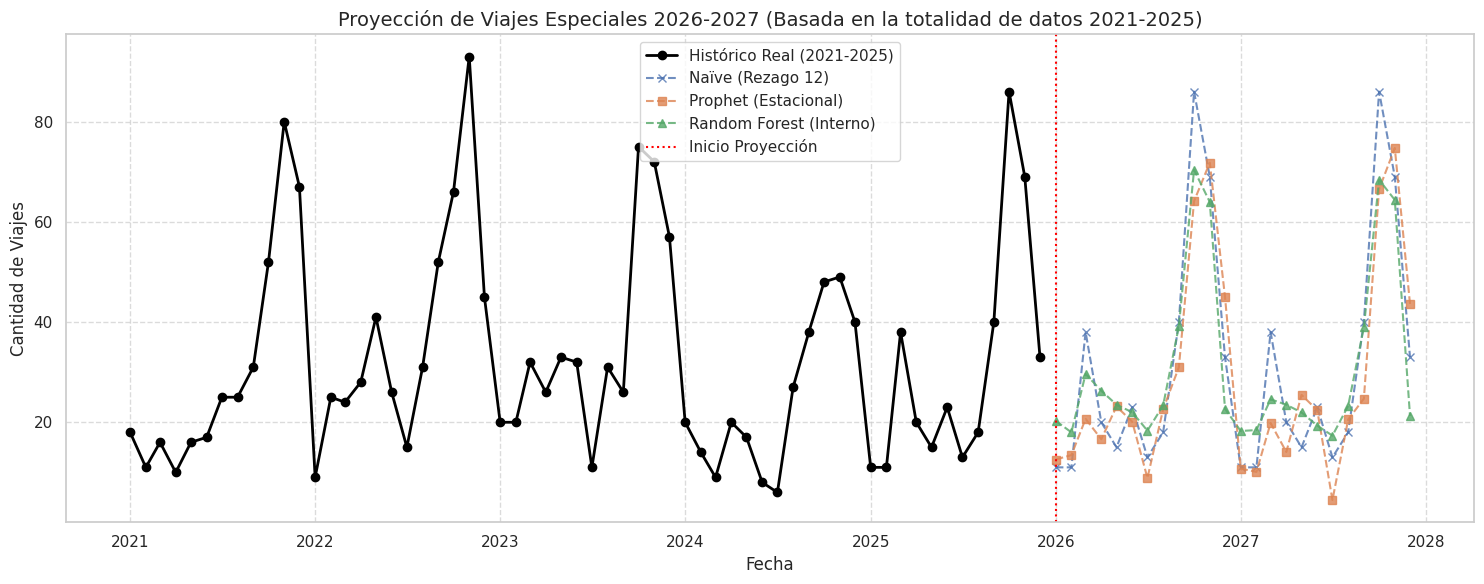

In [ ]:
# @title Código de Proyección 2026-2027
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.ensemble import RandomForestRegressor
import os

print("--- 21. Proyección 2026-2027 (Entrenamiento con todos los datos 2021-2025) ---")

# 1. Preparar base histórica completa
# df_master tiene exactamente los 60 meses desde 2021-01 hasta 2025-12
df_hist = df_master[['mes_anio', 'cantidad_viajes']].copy()

# 2. Naïve Rezago 12 (Repite 2025 dos veces para cubrir 24 meses)
pred_naive = list(df_hist['cantidad_viajes'].values[-12:]) * 2

# 3. Prophet Estacional
df_pro = df_hist.rename(columns={'mes_anio': 'ds', 'cantidad_viajes': 'y'})
mod_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
mod_prophet.fit(df_pro)
future = mod_prophet.make_future_dataframe(periods=24, freq='MS')
pred_prophet = mod_prophet.predict(future)['yhat'].values[-24:]

# 4. Random Forest Interno (Recursivo)
def prep_features_internas(df_in):
    df = df_in.copy()
    df['tendencia'] = np.arange(1, len(df) + 1)
    df['mes'] = df['mes_anio'].dt.month
    df['mes_sin'] = np.sin(2 * np.pi * df['mes'] / 12)
    df['mes_cos'] = np.cos(2 * np.pi * df['mes'] / 12)
    for lag in [1, 2, 3, 6, 12]:
        df[f'viajes_lag_{lag}'] = df['cantidad_viajes'].shift(lag)
    df['viajes_ma_3'] = df['cantidad_viajes'].shift(1).rolling(3).mean()
    df['viajes_ma_6'] = df['cantidad_viajes'].shift(1).rolling(6).mean()
    return df

features_internas = ['tendencia', 'mes_sin', 'mes_cos', 'viajes_lag_1', 'viajes_lag_2',
                     'viajes_lag_3', 'viajes_lag_6', 'viajes_lag_12', 'viajes_ma_3', 'viajes_ma_6']

# Entrenar sobre la historia completa
df_train_feat = prep_features_internas(df_hist)
df_train_clean = df_train_feat.dropna(subset=features_internas + ['cantidad_viajes'])
X_train = df_train_clean[features_internas]
y_train = df_train_clean['cantidad_viajes']

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predicción Recursiva 24 meses hacia adelante
df_sim = df_hist.copy()
pred_rf = []
for _ in range(24):
    next_date = df_sim['mes_anio'].iloc[-1] + pd.DateOffset(months=1)
    new_row = pd.DataFrame({'mes_anio': [next_date], 'cantidad_viajes': [np.nan]})
    df_sim = pd.concat([df_sim, new_row], ignore_index=True)
    df_sim_feat = prep_features_internas(df_sim)
    X_next = df_sim_feat.iloc[[-1]][features_internas]
    pred = rf.predict(X_next)[0]
    pred_rf.append(pred)
    df_sim.loc[df_sim.index[-1], 'cantidad_viajes'] = pred

# 5. Consolidación de Resultados en Tablas
fechas_futuras = pd.date_range(start='2026-01-01', periods=24, freq='MS')
df_proyeccion = pd.DataFrame({
    'Mes': fechas_futuras.strftime('%Y-%m'),
    'Naïve (Rezago 12)': pred_naive,
    'Prophet (Estacional)': pred_prophet,
    'Random Forest (Interno)': pred_rf
})

df_proyeccion_print = df_proyeccion.copy()
df_proyeccion_print['Año'] = fechas_futuras.year
df_totales_anuales = df_proyeccion_print.groupby('Año')[['Naïve (Rezago 12)', 'Prophet (Estacional)', 'Random Forest (Interno)']].sum().reset_index()

print("\n--- 1. Proyección Mensual (2026 - 2027) ---")
display(df_proyeccion.round(1))

print("\n--- 2. Totales Anuales Proyectados ---")
display(df_totales_anuales.round(1))

# 6. Gráfico Comparativo
plt.figure(figsize=(15, 6))
plt.plot(df_hist['mes_anio'], df_hist['cantidad_viajes'], label='Histórico Real (2021-2025)', color='black', marker='o', linewidth=2)
plt.plot(fechas_futuras, pred_naive, label='Naïve (Rezago 12)', linestyle='--', marker='x', alpha=0.8)
plt.plot(fechas_futuras, pred_prophet, label='Prophet (Estacional)', linestyle='--', marker='s', alpha=0.8)
plt.plot(fechas_futuras, pred_rf, label='Random Forest (Interno)', linestyle='--', marker='^', alpha=0.8)

plt.axvline(x=pd.to_datetime('2026-01-01'), color='red', linestyle=':', label='Inicio Proyección')
plt.title('Proyección de Viajes Especiales 2026-2027 (Basada en la totalidad de datos 2021-2025)', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Cantidad de Viajes', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 23. Conclusiones técnicas y limitaciones

* La variable objetivo es la cantidad mensual de viajes especiales.
* La serie histórica construida contiene 60 meses continuos y 1.931 viajes.
* SARIMA con período 12 demostró ser estadísticamente sólido en la validación temporal expansiva.
* Random Forest interno obtuvo el menor error general en la prueba final de 2025.
* Prophet estacional quedó prácticamente empatado con Random Forest en la precisión final.
* Las variables exógenas evaluadas no mejoraron consistentemente el rendimiento de los modelos en etapas fuera de muestra.
* Ningún modelo estadístico o de machine learning anticipó completamente los picos extraordinarios o anómalos de demanda mensual.
* Random Forest genera pronósticos futuros de forma recursiva (realimentándose mes a mes), por lo que la incertidumbre natural aumenta con la longitud del horizonte de proyección.
* El sistema debe utilizarse como apoyo analítico y cuantitativo, y complementarse siempre con la experiencia y el conocimiento operativo del supervisor.